#upload data

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
#unzip
!unzip -q face-mask-lite-dataset.zip  -d data

#import

In [ ]:
import os
from torch.utils.data import random_split, DataLoader
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms as transforms

#make dataset and data loaders

In [ ]:
class FaceMaskRemovalDataset(Dataset):

    def __init__(
        self,
        with_mask_dir,
        without_mask_dir,
        image_size=256,
        threshold=25
    ):

        self.with_mask_dir = with_mask_dir
        self.without_mask_dir = without_mask_dir
        self.threshold = threshold

        self.files = sorted(os.listdir(with_mask_dir))

        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        filename = self.files[idx]

        masked_img = Image.open(
            os.path.join(self.with_mask_dir, filename)
        ).convert("RGB")

        target_img = Image.open(
            os.path.join(self.without_mask_dir, filename.replace('with-mask-default-mask-',''))
        ).convert("RGB")

        masked_tensor = self.transform(masked_img)
        target_tensor = self.transform(target_img)

        # ----------------------------
        # create mask
        # ----------------------------

        diff = torch.abs(masked_tensor - target_tensor)

        mask = (diff.mean(dim=0, keepdim=True) > (self.threshold/255.)).float()
        input_tensor = torch.cat([masked_tensor, mask], dim=0)

        return input_tensor, target_tensor

In [ ]:
dataset = FaceMaskRemovalDataset(
    with_mask_dir="/content/data/with_mask",
    without_mask_dir="/content/data/without_mask",
    image_size=256
)

In [ ]:
# 80% train, 20% test
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)  # reproducible split
)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

#build neural network

In [ ]:
class Generator(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(

            nn.Conv2d(4,64,4,2,1),
            nn.ReLU(True),

            nn.Conv2d(64,128,4,2,1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.Conv2d(128,256,4,2,1),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
        )

        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(256,128,4,2,1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128,64,4,2,1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64,3,4,2,1),

            nn.Tanh()
        )

    def forward(self,x):

        x = self.encoder(x)
        x = self.decoder(x)

        return x

In [ ]:
class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            nn.Conv2d(7,64,4,2,1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(64,128,4,2,1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Conv2d(128,256,4,2,1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),

            nn.Conv2d(256,1,4,1,1)
        )

    def forward(self,x):

        return self.model(x)

In [ ]:
gan_loss = nn.BCEWithLogitsLoss()
l1_loss = nn.L1Loss()

In [ ]:
optimizer_G = optim.Adam(
    G.parameters(),
    lr=2e-4,
    betas=(0.5,0.999)
)

optimizer_D = optim.Adam(
    D.parameters(),
    lr=2e-4,
    betas=(0.5,0.999)
)

In [ ]:
device = "cuda"

G = Generator().to(device)
D = Discriminator().to(device)

In [ ]:
print(f"Current Device Index: {torch.cuda.current_device()}")

#training

In [ ]:
num_epochs=5

In [ ]:
for epoch in range(num_epochs):

    for input, target in train_loader:

        input = input.to(device)
        target = target.to(device)

        ####################################################
        # Split input
        ####################################################

        masked_img = input[:,0:3,:,:]

        mask = input[:,3:4,:,:]

        ####################################################
        # Generator predicts missing region
        ####################################################

        pred_region = G(input)

        ####################################################
        # Build final image
        ####################################################

        fake = masked_img*(1-mask) + pred_region*mask

        ####################################################
        # -------- Train Discriminator --------
        ####################################################

        real_pair = torch.cat([input,target],dim=1)

        fake_pair = torch.cat([input,fake.detach()],dim=1)

        pred_real = D(real_pair)

        pred_fake = D(fake_pair)

        loss_real = gan_loss(
            pred_real,
            torch.ones_like(pred_real)
        )

        loss_fake = gan_loss(
            pred_fake,
            torch.zeros_like(pred_fake)
        )

        loss_D = (loss_real+loss_fake)/2

        optimizer_D.zero_grad()

        loss_D.backward()

        optimizer_D.step()

        ####################################################
        # -------- Train Generator --------
        ####################################################

        fake_pair = torch.cat([input,fake],dim=1)

        pred_fake = D(fake_pair)

        adv_loss = gan_loss(
            pred_fake,
            torch.ones_like(pred_fake)
        )

        reconstruction = (
            torch.abs(fake-target)*mask
        ).sum()/mask.sum().clamp(min=1)

        loss_G = adv_loss + 100*reconstruction

        optimizer_G.zero_grad()

        loss_G.backward()

        optimizer_G.step()

    print(
        f"Epoch {epoch}: "
        f"D={loss_D.item():.4f} "
        f"G={loss_G.item():.4f}"
    )

Epoch 0: D=0.1186 G=29.0569
Epoch 1: D=0.4132 G=25.1148
Epoch 2: D=0.6108 G=20.8751
Epoch 3: D=0.3653 G=25.4359
Epoch 4: D=0.6424 G=20.5160


#inference

In [ ]:
G.eval()

with torch.no_grad():

    for input, target in test_loader:

        input = input.to(device)
        target = target.to(device)

        masked_img = input[:, :3]
        mask = input[:, 3:4]

        # Predict the missing region
        pred_region = G(input)

        # Composite the final image
        output = masked_img * (1 - mask) + pred_region * mask

        break  # Only show the first batch

In [ ]:
def denormalize(img):
    return (img + 1) / 2

In [ ]:
idx = 0

masked = masked_img[idx].cpu()
generated = output[idx].cpu()
target_img = target[idx].cpu()
mask_img = mask[idx].cpu()

In [ ]:
masked = denormalize(masked)
generated = denormalize(generated)
target_img = denormalize(target_img)

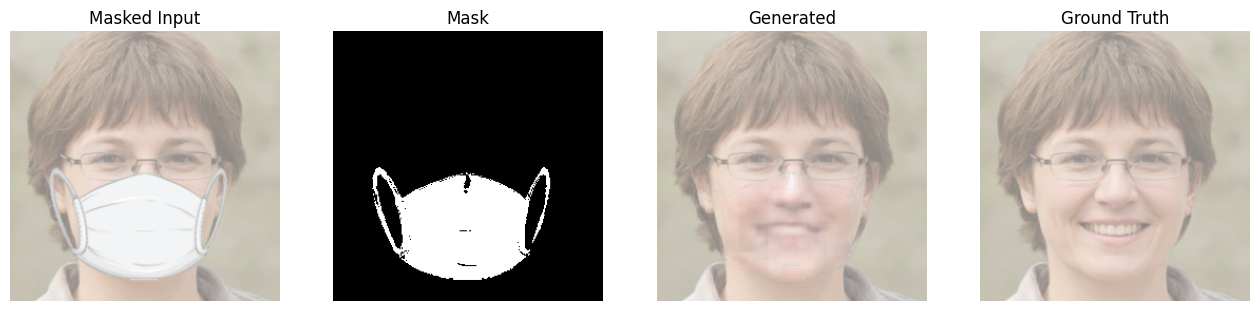

In [ ]:
fig, ax = plt.subplots(1,4,figsize=(16,4))

ax[0].imshow(masked.permute(1,2,0))
ax[0].set_title("Masked Input")
ax[0].axis("off")

ax[1].imshow(mask_img.squeeze(), cmap="gray")
ax[1].set_title("Mask")
ax[1].axis("off")

ax[2].imshow(generated.permute(1,2,0))
ax[2].set_title("Generated")
ax[2].axis("off")

ax[3].imshow(target_img.permute(1,2,0))
ax[3].set_title("Ground Truth")
ax[3].axis("off")

plt.show()

#save model

In [ ]:
torch.save(G.state_dict(), "generator.pth")

In [ ]:
torch.save(D.state_dict(), "discriminator.pth")